In [1]:
import scanpy as sc
import sys
import pandas as pd
import re
from pathlib import Path
import infercnvpy as cnv
from anndata import AnnData
import matplotlib.pyplot as plt
# setting directory
PROJECT_DIR = Path.home() / "project/crc-pm"
CODE_DIR = PROJECT_DIR / "code"
OUTDIR = PROJECT_DIR / "result/fork1-OnlyCRC"
FIGDIR = OUTDIR / "figures"
sc.settings.figdir = FIGDIR
# enabling import src
sys.path.insert(0, str(CODE_DIR))
import src

In [2]:
adata = sc.read_h5ad(OUTDIR/'ready_for_anno.h5ad')

In [3]:
# 由于肿瘤太细碎了, 导致其他亚群分型不太好, 准备分出不同的大类后再进行细分
# 主要谱系的dict
marker_dict = {
    "Epithelium": ["EPCAM", "KRT8", "KRT18", "KRT19"],
    "T_NK": ["CD3D", "CD3E", "TRAC", "NKG7", "GNLY", "KLRD1"],
    "B": ["CD79A", "CD79B", "MS4A1", "CD19"],
    "Plasma": ["MZB1", "JCHAIN", "SDC1", "XBP1"],
    "Mono_Macro_DC": ["LYZ", "LST1", "CTSS", "CD14", "C1QA", "CD1C", "FCER1A"],
    "Neutrophil": ["CSF3R", "FCGR3B", "CXCR2", "FPR1"],
    "Mast": ["TPSAB1", "TPSB2", "CPA3", "KIT", "MS4A2"],
    "Fibroblast": ["COL1A1", "COL1A2", "COL3A1", "DCN", "LUM"],
    "Endothelial": ["PECAM1", "CDH5", "VWF", "CLDN5"],
    "Pericyte_SMC": ["RGS5", "PDGFRB", "CSPG4", "ACTA2", "TAGLN", "MYH11"],
    "Schwann": ['S100B', 'SOX10', 'PLP1', 'SLC1A3'],
    "RBC" : ['HBA1', 'HBA2', 'HBB', 'ALAS2'],
    "pDC" : ['CLEC4C', 'TCF4', 'IL3RA', 'GZMB']
}

正在绘制：Epithelium / EPCAM
正在绘制：Epithelium / KRT8
正在绘制：Epithelium / KRT18
正在绘制：Epithelium / KRT19
正在绘制：T_NK / CD3D
正在绘制：T_NK / CD3E
正在绘制：T_NK / TRAC
正在绘制：T_NK / NKG7
正在绘制：T_NK / GNLY
正在绘制：T_NK / KLRD1
正在绘制：B / CD79A
正在绘制：B / CD79B
正在绘制：B / MS4A1
正在绘制：B / CD19
正在绘制：Plasma / MZB1
正在绘制：Plasma / JCHAIN
正在绘制：Plasma / SDC1
正在绘制：Plasma / XBP1
正在绘制：Mono_Macro_DC / LYZ
正在绘制：Mono_Macro_DC / LST1
正在绘制：Mono_Macro_DC / CTSS
正在绘制：Mono_Macro_DC / CD14
正在绘制：Mono_Macro_DC / C1QA
正在绘制：Mono_Macro_DC / CD1C
正在绘制：Mono_Macro_DC / FCER1A
正在绘制：Neutrophil / CSF3R
正在绘制：Neutrophil / FCGR3B
正在绘制：Neutrophil / CXCR2
正在绘制：Neutrophil / FPR1
正在绘制：Mast / TPSAB1
正在绘制：Mast / TPSB2
正在绘制：Mast / CPA3
正在绘制：Mast / KIT
正在绘制：Mast / MS4A2
正在绘制：Fibroblast / COL1A1
正在绘制：Fibroblast / COL1A2
正在绘制：Fibroblast / COL3A1
正在绘制：Fibroblast / DCN
正在绘制：Fibroblast / LUM
正在绘制：Endothelial / PECAM1
正在绘制：Endothelial / CDH5
正在绘制：Endothelial / VWF
正在绘制：Endothelial / CLDN5
正在绘制：Pericyte_SMC / RGS5
正在绘制：Pericyte_SMC / PDGFRB
正在绘制：Pericyte_SMC / CSPG4
正在绘

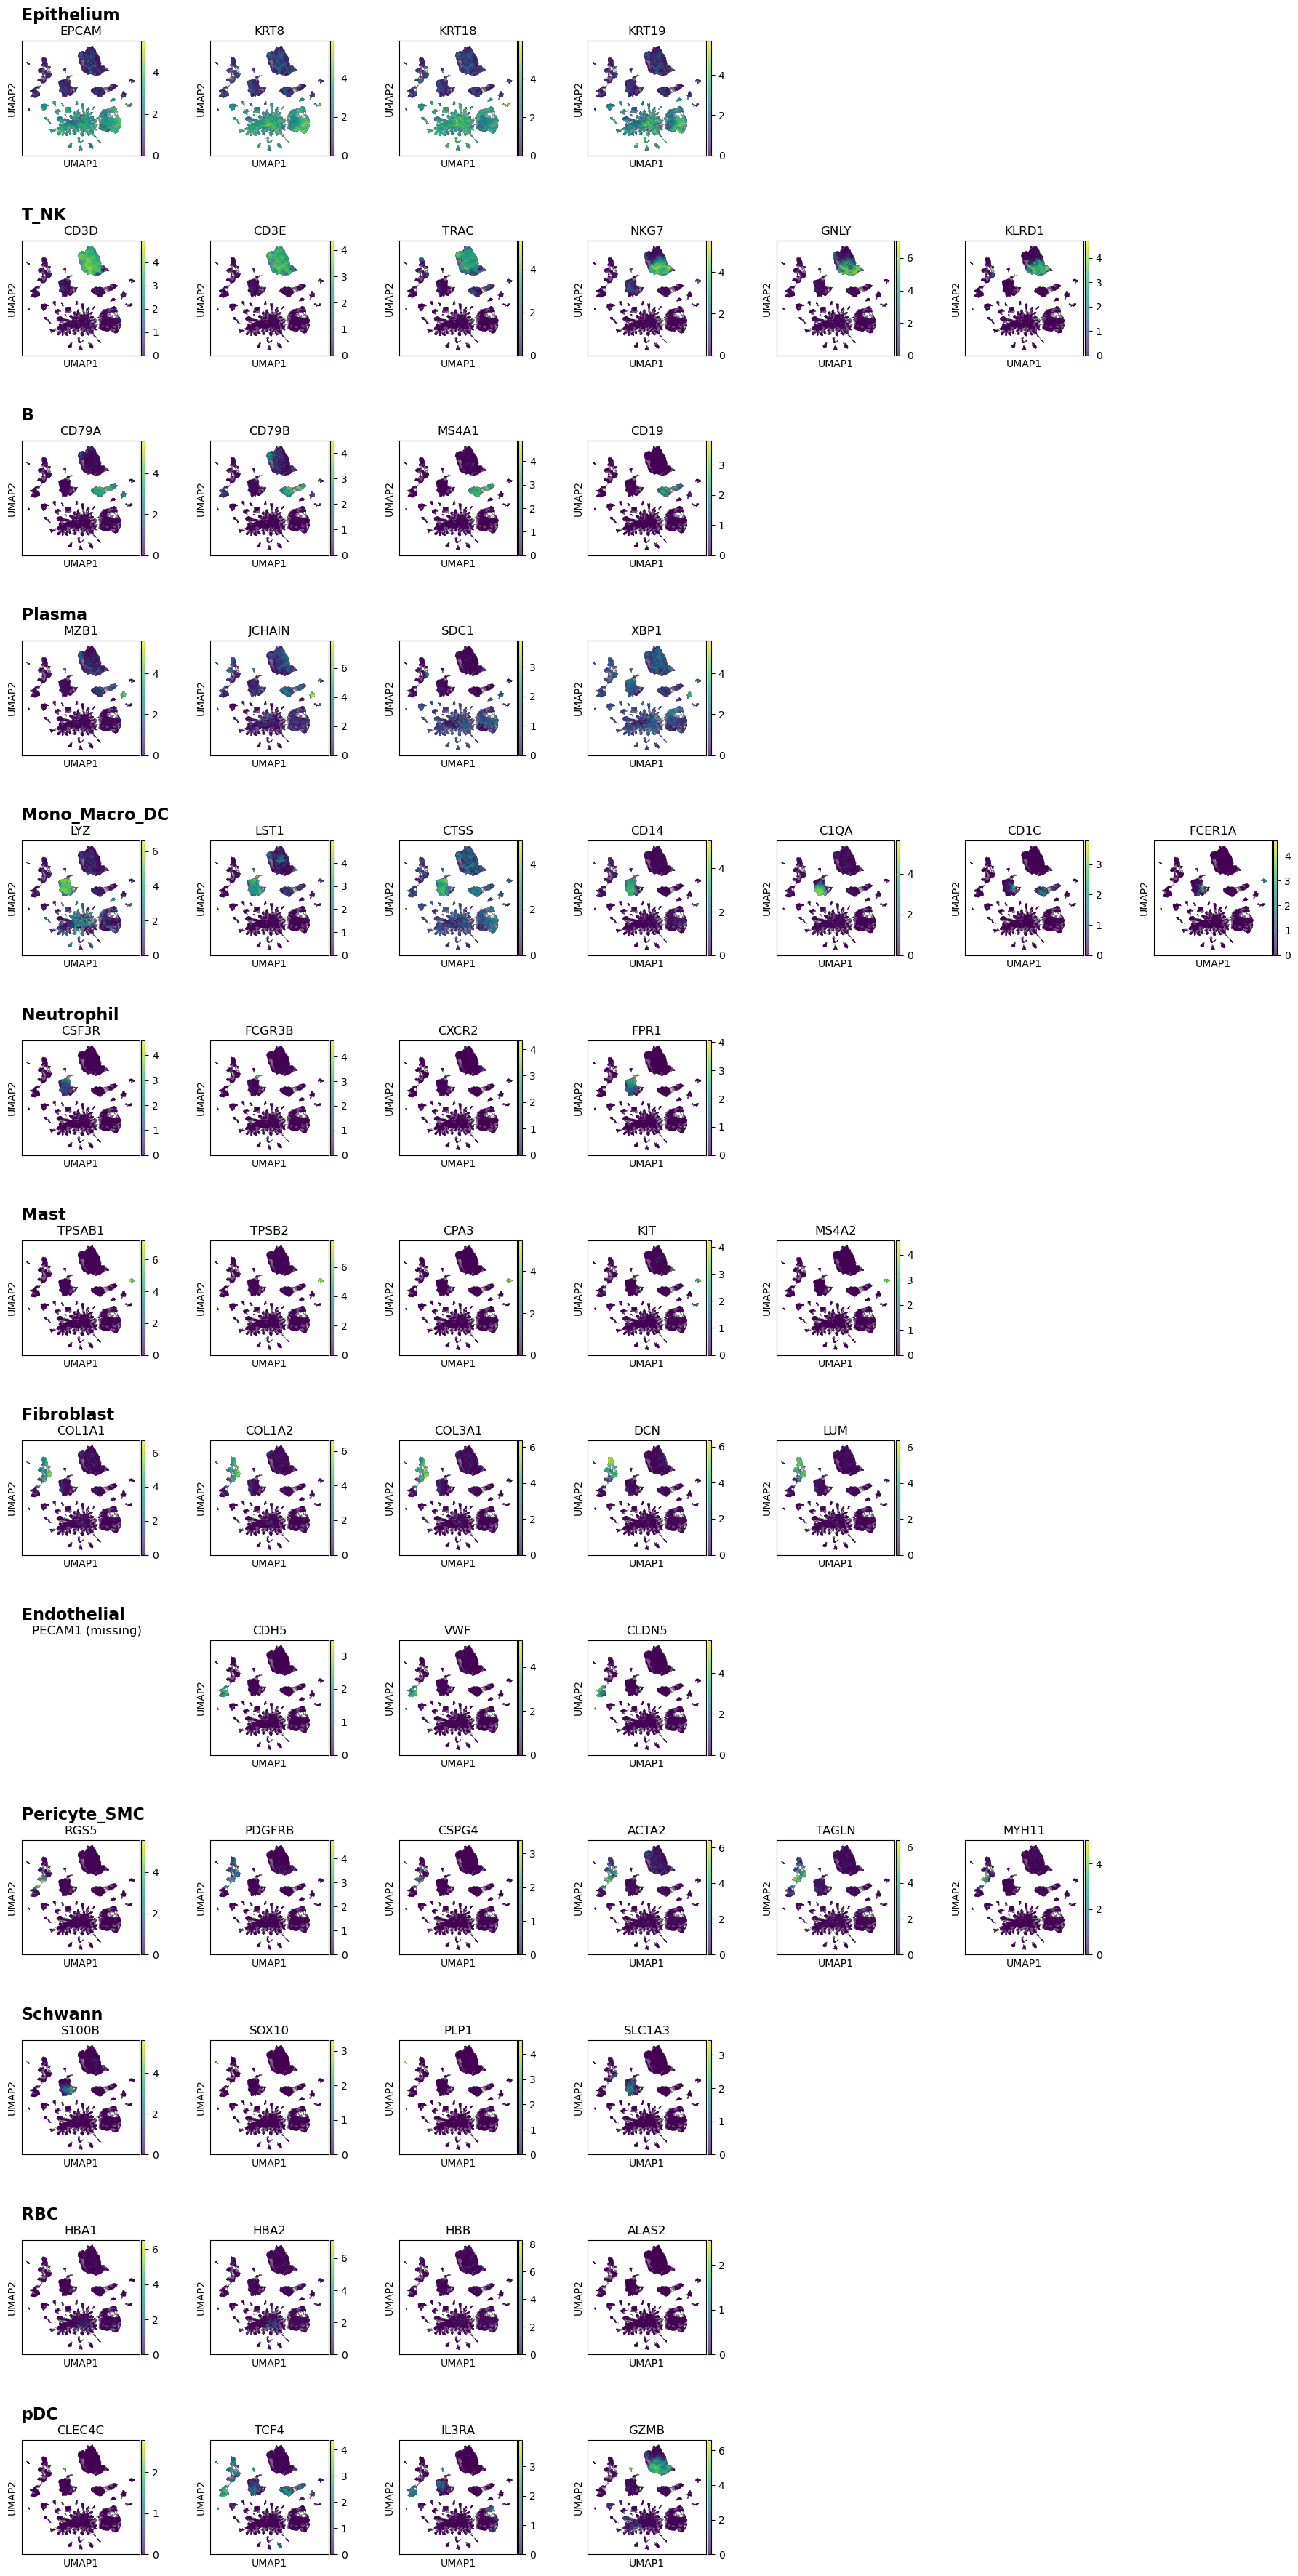

In [4]:
# 整理一下 TODO

nrows = len(marker_dict)
ncols = max(len(markers) for markers in marker_dict.values())

fig = plt.figure(figsize=(3.2 * ncols, 3.5 * nrows))
outer = fig.add_gridspec(nrows, 1, hspace=0.35)

for row, (subtype, subtype_markers) in enumerate(marker_dict.items()):
    # 每组分成标题行和 UMAP 行
    grid = outer[row].subgridspec(
        2, ncols,
        height_ratios=[0.15, 1],
        hspace=0.25,
        wspace=0.45,
    )

    title_ax = fig.add_subplot(grid[0, :])
    title_ax.axis("off")
    title_ax.text(
        0, 0.5, subtype,
        fontsize=16,
        fontweight="bold",
        ha="left",
        va="center",
    )

    available = set(adata.var["gene_name"].dropna())

    for col, gene in enumerate(subtype_markers):
        ax = fig.add_subplot(grid[1, col])

        print(f"正在绘制：{subtype} / {gene}", flush=True)

        if gene not in available:
            ax.set_title(f"{gene} (missing)")
            ax.axis("off")
            continue

        try:
            sc.pl.umap(
                adata,
                gene_symbols="gene_name",
                color=gene,
                layer="log1p",
                use_raw=False,
                add_outline=True,
                title=gene,
                ax=ax,
                show=False,
            )
        except Exception as e:
            print(
                f"绘图失败：{subtype} / {gene}\n"
                f"{type(e).__name__}: {e}",
                flush=True,
            )
            ax.set_title(f"{gene} (failed)")
            ax.axis("off")
plt.show()
fig.savefig(FIGDIR / "major_lineage_markers.png", dpi=200, bbox_inches="tight")

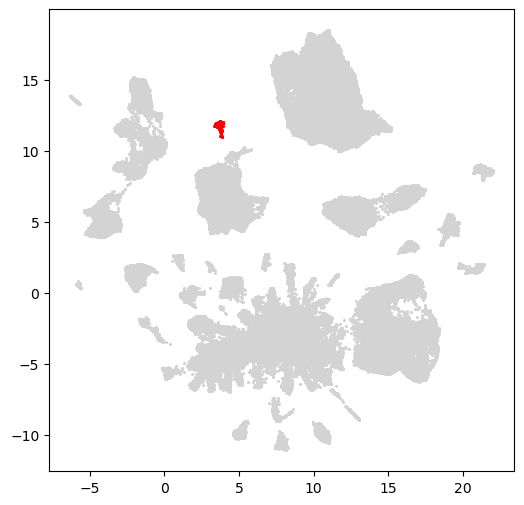

In [5]:
# TODO 整理一下成函数
import matplotlib.pyplot as plt
xy = adata.obsm['X_umap']
is_red = adata.obs['leiden_0.1'].astype(str).eq('16').to_numpy()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(
    xy[~is_red, 0], xy[~is_red, 1],
    c='lightgrey', s=5, linewidths=0, zorder=1,
)
ax.scatter(
    xy[is_red, 0], xy[is_red, 1],
    c='red', s=5, linewidths=0, zorder=2,
)
plt.show()


In [6]:
# 从leiden 0.05开始生成
leiden01_dict = {
    '0':'Epithelium',
    '1':'Epithelium',
    '2':'Epithelium',
    '3':'Epithelium',
    '4':'Epithelium',
    '5':'Epithelium',
    '6':'Epithelium',
    '7':'Epithelium',
    '8':'Myeloid',
    '9':'Epithelium',
    '10':'T_NK_ILC',
    '11':'Epithelium',
    '12':'Fibroblast_Pericyte',
    '13':'Endothelium',
    '14':'Schwann',
    '15':'Mast',
    '16':'pDC',
    '17':'B',
    '18':'Plasma',
    '19':'Epithelium',
    '20':'Epithelium',
    '21':'Epithelium',
    '22':'Epithelium',
}

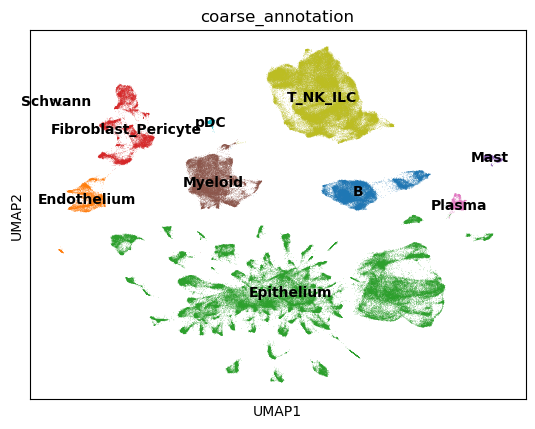

In [7]:
adata.obs['coarse_annotation'] = adata.obs['leiden_0.1'].map(leiden01_dict)
sc.pl.umap(adata, color = 'coarse_annotation',legend_loc = 'on data')

### Pipeline for inferCNV

In [8]:
# 准备position信息
position = src.GTFMapping.id2pos(list(adata.var.index), flavour='chr')

adata.var['chromosome'] = [p[0] if p else None for p in position]
adata.var['start'] = [p[1] if p else None for p in position]
adata.var['end'] = [p[2] if p else None for p in position]
adata.var['strand'] = [p[3] if p else None for p in position]

/tmp/ipykernel_444416/1414516508.py:2: UserWarning: 235 gene IDs not found in GRCh38.111: ENSG00000112096, ENSG00000116883, ENSG00000130489, ENSG00000130723, ENSG00000154537, ENSG00000163009, ENSG00000167945, ENSG00000182230, ENSG00000182584, ENSG00000184258, ENSG00000186354, ENSG00000203386, ENSG00000203812, ENSG00000203886, ENSG00000204092, ENSG00000204187, ENSG00000204683, ENSG00000205663, ENSG00000205664, ENSG00000206532, ENSG00000213240, ENSG00000213863, ENSG00000213865, ENSG00000214215, ENSG00000215159, ENSG00000215271, ENSG00000221972, ENSG00000221995, ENSG00000223414, ENSG00000223821, ENSG00000223929, ENSG00000224050, ENSG00000224638, ENSG00000224739, ENSG00000224959, ENSG00000225554, ENSG00000225932, ENSG00000225986, ENSG00000226155, ENSG00000226377, ENSG00000226380, ENSG00000226751, ENSG00000227220, ENSG00000227468, ENSG00000227603, ENSG00000228106, ENSG00000228439, ENSG00000228569, ENSG00000228614, ENSG00000228651, ENSG00000228906, ENSG00000229245, ENSG00000229611, ENSG00000

In [9]:
# provide immune cell normal cell.
cnv.tl.infercnv(
    adata,
    layer = 'log1p',
    reference_key = 'coarse_annotation',
    reference_cat=[
        'T_NK_ILC','Myeloid','Plasma','B','Mast','pDC',
    ],
    window_size=250,
)

  0%|          | 0/52 [00:00<?, ?it/s]

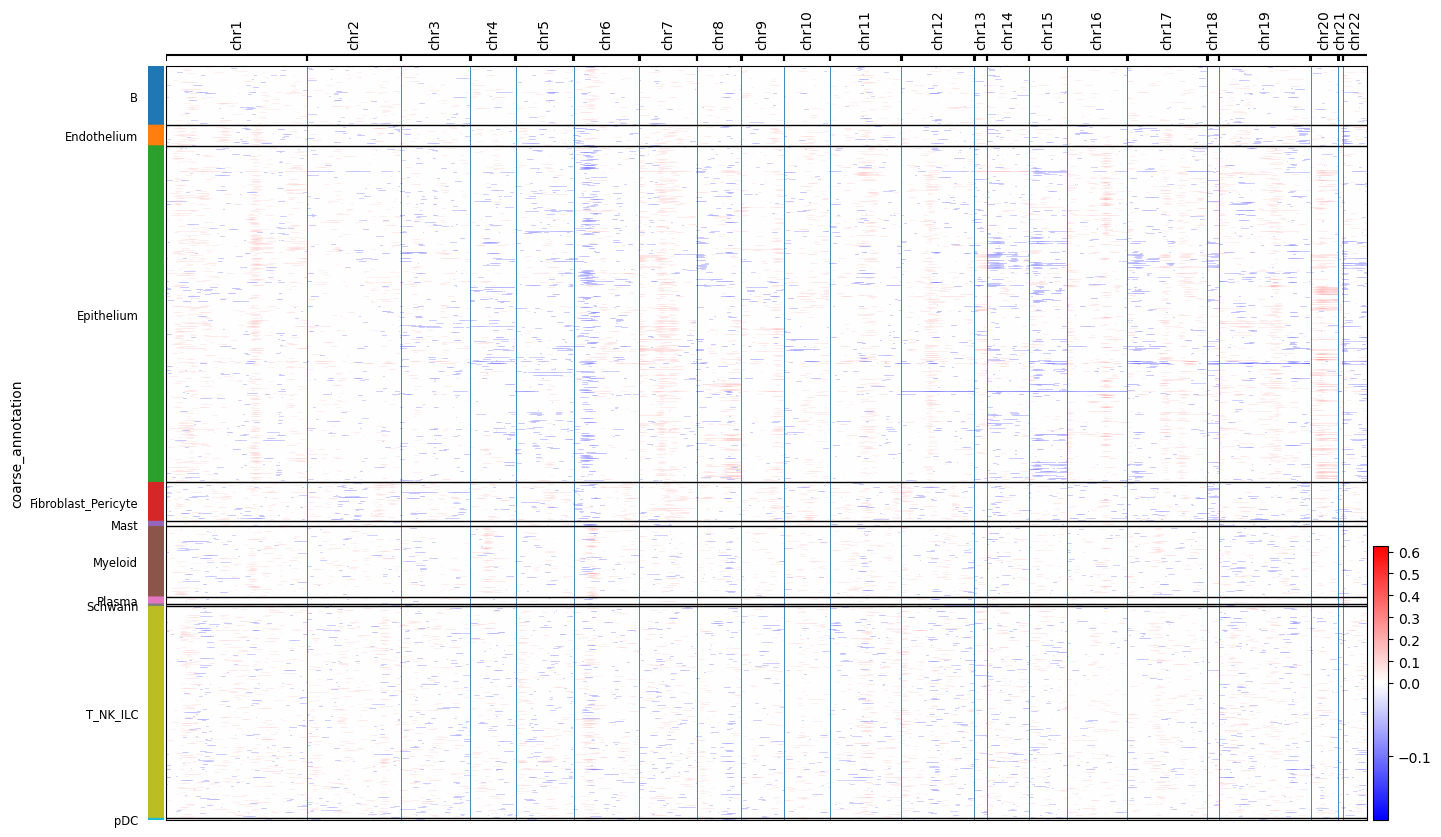

In [10]:
cnv.pl.chromosome_heatmap(adata, groupby='coarse_annotation')

In [ ]:
cnv.tl.pca(adata)
cnv.pp.neighbors(adata)
cnv.tl.umap(adata)
cnv.tl.leiden(adata, resolution = 0.1)
cnv.tl.cnv_score(adata)
sc.tl.dendrogram(adata)

/home/zhekai/miniconda3/envs/pm/lib/python3.13/site-packages/infercnvpy/tl/__init__.py:24: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  return sc.tl.leiden(


/home/zhekai/miniconda3/envs/pm/lib/python3.13/site-packages/infercnvpy/pl/_chromosome_heatmap.py:74: UserWarning: You’re trying to run this on 1861 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  return_ax_dic = sc.pl.heatmap(


categories: 0, 1, 2, etc.
var_group_labels: chr1, chr2, chr3, etc.


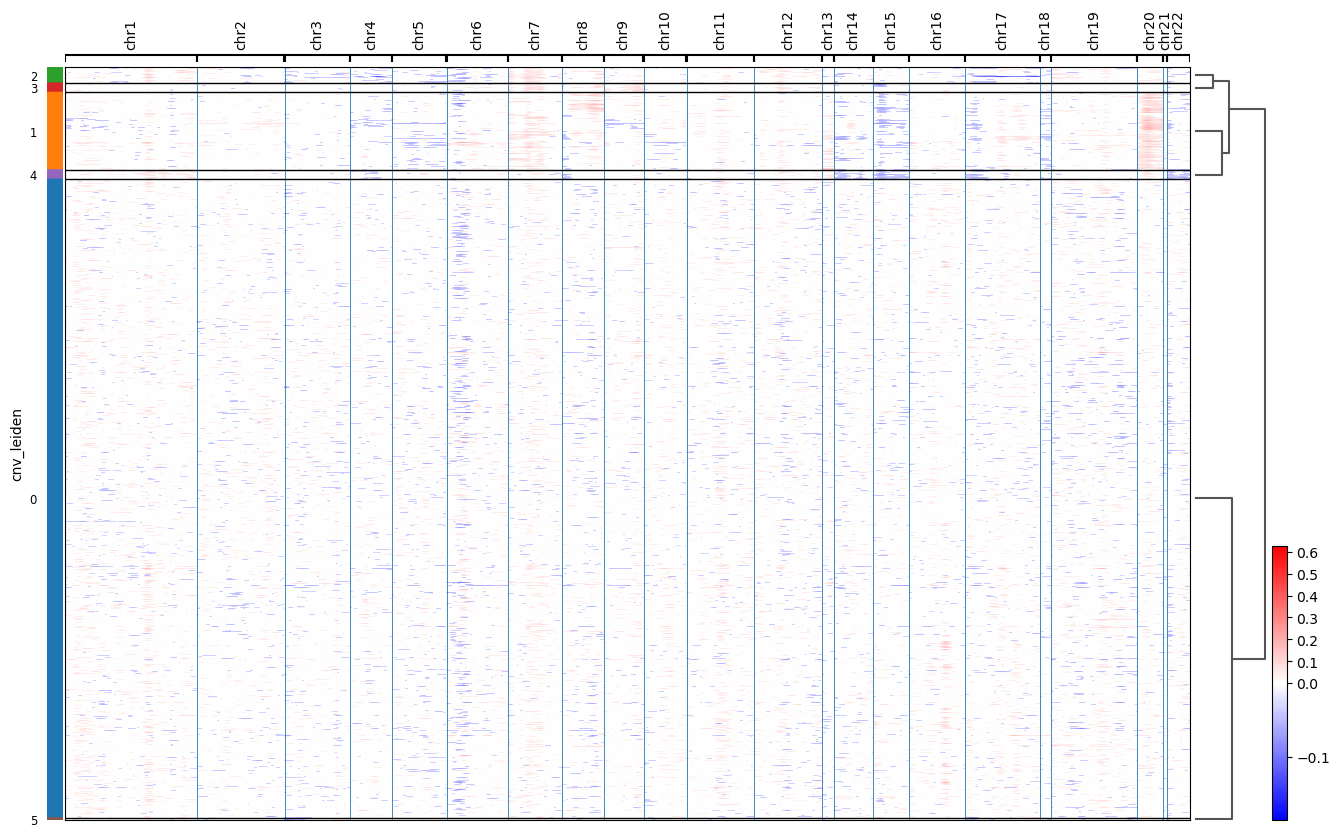

In [12]:
cnv.pl.chromosome_heatmap(adata, groupby="cnv_leiden", dendrogram=True)

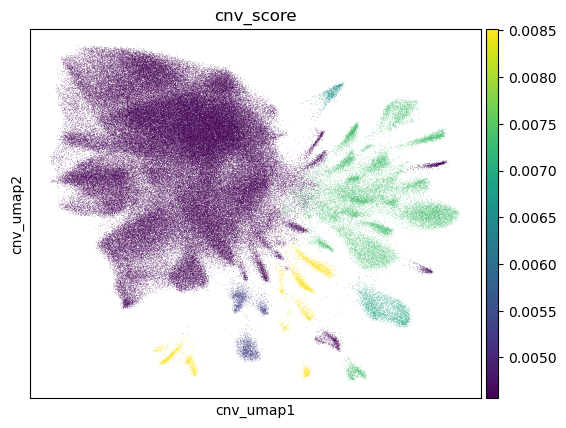

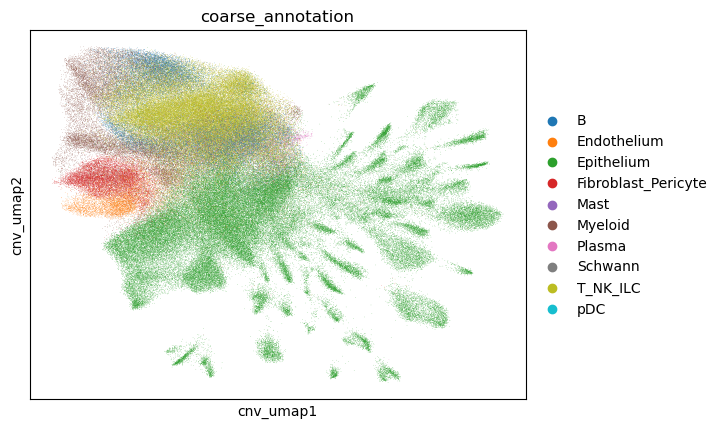

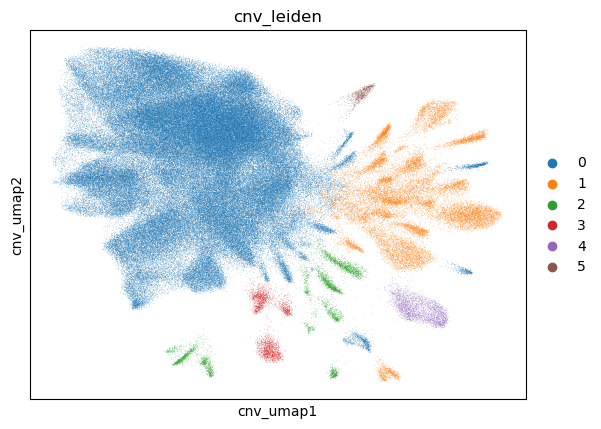

In [17]:
cnv.pl.umap(adata, color="cnv_score")
cnv.pl.umap(adata, color="coarse_annotation")
cnv.pl.umap(adata, color="cnv_leiden")

In [25]:
adata.obs['cnv_status'] = adata.obs['cnv_leiden'].map(
    {
        '0':'normal',
        '1':'abnormal',
        '2':'abnormal',
        '3':'abnormal',
        '4':'abnormal',
        '5':'abnormal',
    }
)

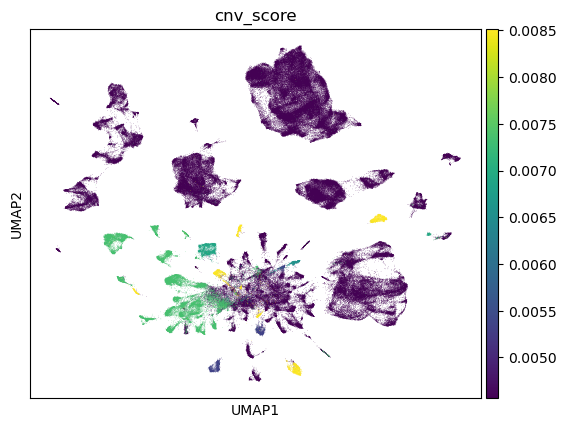

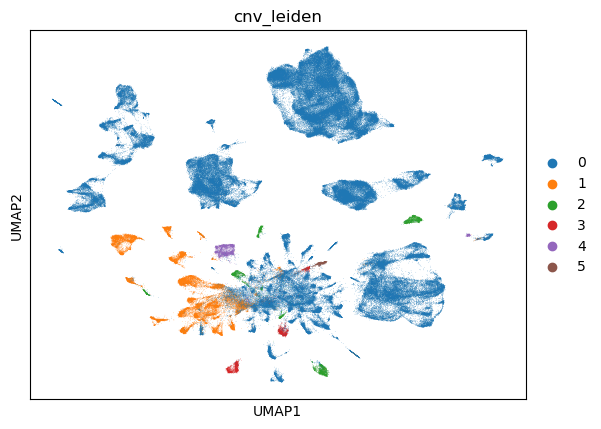

In [ ]:
sc.pl.umap(adata, color="cnv_score")
sc.pl.umap(adata, color="cnv_leiden")

In [26]:
adata.write_h5ad(OUTDIR / "coarse_annotated.h5ad", compression="lzf")